# Desarrollo 02: lago urbano en China, la primera mejora del algoritmo

El notebook 01 dejo el metodo mas simple que funciono en el ejemplo mas facil, el rio Meguro. Aqui se sigue la regla de esta carpeta: **se copia ese notebook cambiando solo la configuracion, se mira que falla, y se cambia solo lo que el fallo obliga**.

**Resultado.** En las 5 secciones (234 fotos, 173 con lectura manual), **la v2 da un error absoluto medio de 0.68 cm y 94.6 % en +-2 cm**; la copia sin cambios lee sobre la mira seca: 31.22 cm y 0.6 % en +-2 cm con ese mismo cero. En la **serie completa, la v2 da 0.57 cm, 97.65 % en +-2 cm y 99.33 % en +-5 cm** (2682 fotos). Se estima con la referencia una constante de cero. **En Meguro, con el valor neutro `FOTO_SECA = None`, no cambia ninguna de las 53 lecturas; con los parametros activos empeora** (1.49 cm y 84 % en +-2 cm, frente a 1.11 cm y 92 %), asi que alli la memoria debe ir apagada. No es una prueba del todo a ciegas: seccion 4.2.

| Parte | |
|---|---|
| 1. Copia del notebook 01 | mismo codigo, solo cambia la configuracion. Tabla de valores Meguro / China |
| 2. Problemas | que salio mal, con figuras y su causa, y que no dio problema |
| 3. Cambios al codigo | cada cambio con su fallo y su diff literal; lista de lineas comprobada contra el notebook 01 |
| 4. Resultados en China | por seccion, v1 y v2 (tabla principal), serie completa aparte, video |
| 5. Comprobacion en Meguro | el mismo codigo v2 en las 53 fotos del ejemplo 1, foto por foto |
| 6. Limitaciones | que queda sin resolver |

**De donde sale cada numero.** Las partes 1 a 3 y la tabla principal se calculan solo sobre **5 secciones** de la serie (234 fotos). La **serie completa** (3315 fotos) es una validacion final de la v2 y se da aparte, en la seccion 4.3.

# 1. Copia del notebook 01

## 1.1 Preparacion y datos

**Datos.** [Zenodo 10812125](https://zenodo.org/records/10812125), CC BY 4.0: 3315 fotos de 3840 x 2160 px de una camara fija sobre la mira de un lago urbano del sur de China, una cada 15 min, del 27-may al 6-jul-2023; de noche la camara pasa a infrarrojo. La lectura manual de 2691 fotos es la referencia, y **solo se abre en la seccion 4.2**.

**Las secciones.** Son bloques continuos de la serie, sin quitar ninguna foto de dentro. **Se eligieron solo mirando las imagenes**, en hojas con varias fotos de cada dia, y con una regla fijada antes de medir:

| Seccion | Bloque | Como se eligio |
|---|---|---|
| dia, agua quieta | 27-may 06:00 a 17:30 | agua quieta y reflejo claro: el primer dia de la serie |
| dia, agua rizada | 11-jun 09:30 a 16:00 | el primer bloque de dia de unas 6 h en que no se ve reflejo |
| noche | 27-may 20:00 a 28-may 05:00 | infrarrojo: la primera noche completa |
| cambio brusco | 4-jul 11:00 a 20:00 | el agua sube ~17 cm en menos de dos horas, con lluvia; es la mayor crecida visible |
| vaciado | 19-jun, todo el dia | el agua mas baja de la serie; incluye la foto seca de la seccion 3 |

**Cautela sobre la eleccion.** La referencia no se habia abierto al fijarlas. Si se conocia, de pruebas sin referencia, que el metodo falla en parte de las fotos de finales de mayo; por eso se uso la regla "el primero" y no un dia elegido a mano, y ese dia queda dentro.

Con `SOLO_SECCIONES = True` el notebook corre en pocos minutos y lee la serie completa de un CSV guardado; con `False` la vuelve a medir.

In [1]:
import ast
import difflib
import json
import os
import sys
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

sys.path.insert(0, os.path.join("..", "herramientas"))
import escritor_video                     # escribe H.264 por una tuberia a ffmpeg (cv2.VideoWriter no sirve aqui)

plt.rcParams.update({"figure.dpi": 90, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#8a8984", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "axes.labelcolor": "#52514e"})

# Colores de las figuras: rojo = linea de agua, azul = ventanas, amarillo = marcas y lectura a ojo
ROJO, AZUL, NARANJA, AMARILLO = "#e34948", "#2a78d6", "#eb6834", "#eda100"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"

SOLO_SECCIONES = True     # True: solo las secciones, la serie completa se lee del CSV guardado. False: se vuelve a medir la serie completa

DATOS = os.path.join("..", "01_zenodo_lago_china", "datos", "SAM_water_level_Dataset")
CARPETA_FOTOS = os.path.join(DATOS, "Staff gauge images")
EXCEL_REFERENCIA = os.path.join(DATOS, "In-situ water levels", "In-situ & simulated water levels.xlsx")   # solo se abre en la seccion 4.2
SALIDAS = "salidas"
os.makedirs(SALIDAS, exist_ok=True)

TEXTO_NIVEL = (0, 0, 0, 0)                # x0, y0, x1, y1: en este ejemplo no hay nivel impreso que tapar


def leer(archivo):
    img = cv2.imread(os.path.join(CARPETA_FOTOS, archivo))
    x0, y0, x1, y1 = TEXTO_NIVEL
    img[y0:y1, x0:x1] = 0
    return img


def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def gris(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)


def hora_de(archivo):
    # P23052700112410.jpg -> 2023-05-27 00:11:24 (hora local que imprime la camara)
    return datetime.strptime(os.path.basename(archivo)[1:13], "%y%m%d%H%M%S")


fotos = sorted(os.path.relpath(os.path.join(r, f), CARPETA_FOTOS).replace("\\", "/")
               for r, _, fs in os.walk(CARPETA_FOTOS) for f in fs if f.endswith(".jpg"))
print("%d fotos, de %s a %s" % (len(fotos), hora_de(fotos[0]), hora_de(fotos[-1])))

# >>> AJUSTABLE <<< las secciones: bloques continuos, elegidos solo con la imagen
SECCIONES = {"dia, agua quieta": ("2023-05-27 06:00", "2023-05-27 17:30"),
             "dia, agua rizada": ("2023-06-11 09:30", "2023-06-11 16:00"),
             "noche": ("2023-05-27 20:00", "2023-05-28 05:00"),
             "cambio brusco": ("2023-07-04 11:00", "2023-07-04 20:00"),
             "vaciado": ("2023-06-19 00:00", "2023-06-19 23:59")}


def seccion_de(archivo):
    h = hora_de(archivo)
    for nombre, (t0, t1) in SECCIONES.items():
        if pd.Timestamp(t0) <= h <= pd.Timestamp(t1):
            return nombre
    return None


fotos_s = [a for a in fotos if seccion_de(a) is not None]
print("En las secciones: %d fotos" % len(fotos_s), {s: sum(seccion_de(a) == s for a in fotos_s) for s in SECCIONES})

3315 fotos, de 2023-05-27 00:11:24 a 2023-07-06 10:56:17
En las secciones: 234 fotos {'dia, agua quieta': 46, 'dia, agua rizada': 26, 'noche': 36, 'cambio brusco': 36, 'vaciado': 90}


## 1.2 Una foto

La mira tiene un numero cada 10 cm y una marca en E cada 2 cm. Debajo de la linea de agua se ve su reflejo.

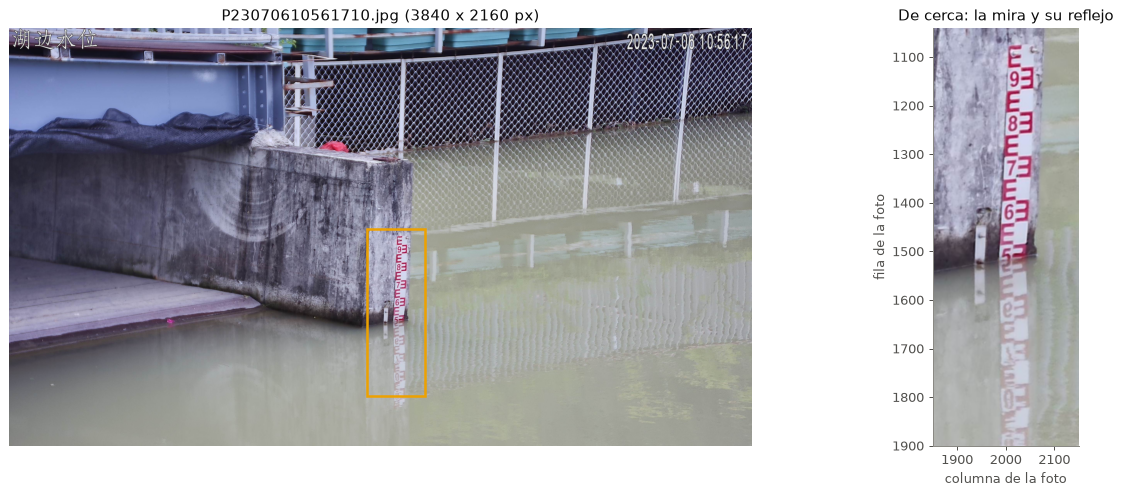

In [2]:
FOTO = "20230706/images/P23070610561710.jpg"     # la foto con la que se explica el metodo
img = leer(FOTO)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [2.6, 1]})
ax[0].imshow(rgb(img)); ax[0].axis("off")
ax[0].set_title("%s (%d x %d px)" % (os.path.basename(FOTO), img.shape[1], img.shape[0]), color=TINTA)
ax[0].add_patch(Rectangle((1850, 1040), 300, 860, fill=False, ec=AMARILLO, lw=2))
ax[1].imshow(rgb(img[1040:1900, 1850:2150]), extent=[1850, 2150, 1900, 1040], interpolation="bicubic")
ax[1].set_title("De cerca: la mira y su reflejo", color=TINTA)
ax[1].set_xlabel("columna de la foto"); ax[1].set_ylabel("fila de la foto")
plt.tight_layout()

## 1.3 Configuracion: cuatro puntos y dos niveles

Igual que en el notebook 01: a mano, una vez, sobre la foto de agua mas baja. Son los bordes de la mira y dos marcas conocidas: 95 y 25 cm.

Esquinas: sup_izq (2005.3, 1119.5), sup_der (2059.4, 1119.5), inf_der (2032.2, 1762.0), inf_izq (1979.2, 1762.0)


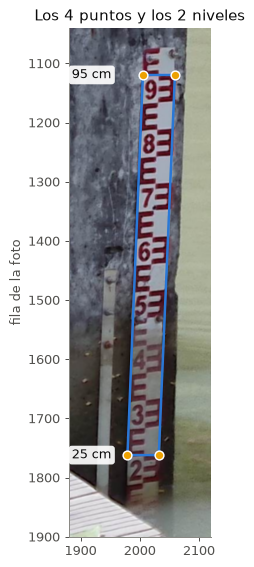

In [3]:
# >>> AJUSTABLE <<< (x, fila) de cada borde de la placa, leidos a ojo sobre ampliaciones de la foto de agua mas baja
BORDE_IZQ = [(2002, 1200), (1980, 1742)]
BORDE_DER = [(2056, 1200), (2033, 1742)]

# >>> AJUSTABLE <<< dos niveles conocidos (cm de mira) y la fila donde estan, leidos a ojo
NIVEL_SUP, FILA_SUP = 95.0, 1119.5        # marca de 95 cm
NIVEL_INF, FILA_INF = 25.0, 1762.0        # marca de 25 cm


def recta_por(puntos):
    (xa, ya), (xb, yb) = puntos
    return lambda y: xa + (np.asarray(y, float) - ya) * (xb - xa) / (yb - ya)


x_izq, x_der = recta_por(BORDE_IZQ), recta_por(BORDE_DER)
SUP_IZQ, SUP_DER = (float(x_izq(FILA_SUP)), FILA_SUP), (float(x_der(FILA_SUP)), FILA_SUP)
INF_DER, INF_IZQ = (float(x_der(FILA_INF)), FILA_INF), (float(x_izq(FILA_INF)), FILA_INF)
print("Esquinas: sup_izq (%.1f, %.1f), sup_der (%.1f, %.1f), inf_der (%.1f, %.1f), inf_izq (%.1f, %.1f)"
      % (*SUP_IZQ, *SUP_DER, *INF_DER, *INF_IZQ))

ref = leer("20230619/images/P23061910562010.jpg")       # la foto de agua mas baja
fig, a0 = plt.subplots(figsize=(4.4, 6.4))
a0.imshow(rgb(ref[1040:1900, 1880:2120]), extent=[1880, 2120, 1900, 1040], interpolation="bicubic")
a0.add_patch(Polygon([SUP_IZQ, SUP_DER, INF_DER, INF_IZQ], closed=True, fill=False, ec=AZUL, lw=2))
for (x, y), texto in [(SUP_IZQ, "95 cm"), (INF_IZQ, "25 cm")]:
    a0.plot([x, x + (SUP_DER[0] - SUP_IZQ[0])], [y, y], "o", ms=7, mfc=AMARILLO, mec="white", mew=1.2)
    a0.text(1885, y, texto, color=TINTA, va="center", bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.92))
a0.set_title("Los 4 puntos y los 2 niveles", color=TINTA); a0.set_ylabel("fila de la foto")
plt.tight_layout()

## 1.4 El tablero enderezado

`Tablero` es la clase del notebook 01. Aqui 9 filas son 1 cm, y cada fila vale siempre el mismo nivel.

Tablero de 54 columnas x 900 filas


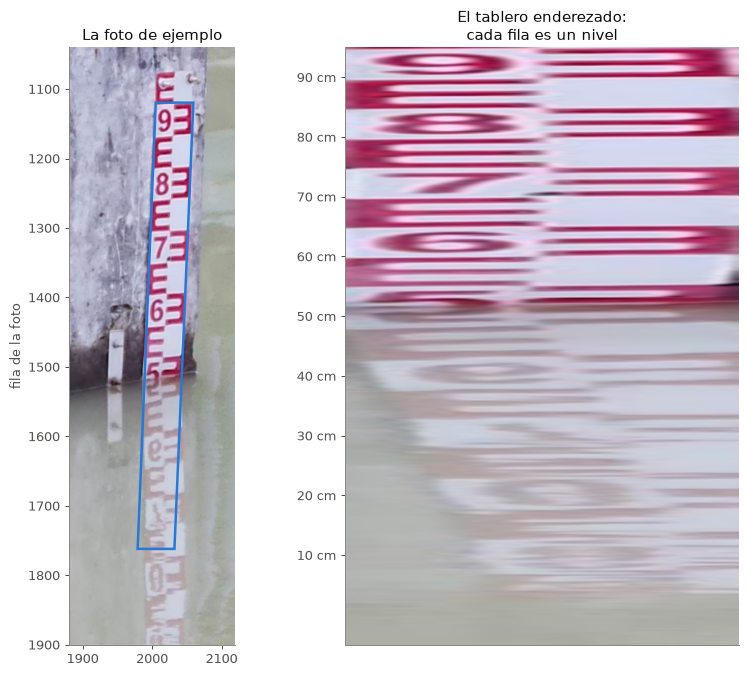

In [4]:
class Tablero:
    # 4 puntos + 2 niveles -> tablero enderezado con lados paralelos: cada fila es un nivel fijo
    def __init__(self, sup_izq, sup_der, inf_der, inf_izq, nivel_sup, nivel_inf, px_por_cm, ancho_px, extra_cm):
        self.nivel_sup, self.px_por_cm = float(nivel_sup), float(px_por_cm)
        alto = (nivel_sup - nivel_inf) * px_por_cm
        src = np.float64([sup_izq, sup_der, inf_der, inf_izq])
        dst = np.float64([[0, 0], [ancho_px, 0], [ancho_px, alto], [0, alto]])
        A = np.hstack([src, np.ones((4, 1))])
        self.M = np.array([np.linalg.lstsq(A, dst[:, i], rcond=None)[0] for i in (0, 1)])   # afin por minimos cuadrados
        self.M_inv = cv2.invertAffineTransform(self.M)
        self.tam = (int(ancho_px), int(alto + extra_cm * px_por_cm))

    def enderezar(self, img):
        return cv2.warpAffine(img, self.M, self.tam, flags=cv2.INTER_LINEAR)

    def fila_de(self, nivel):
        return (self.nivel_sup - nivel) * self.px_por_cm

    def nivel_de(self, fila):
        return self.nivel_sup - fila / self.px_por_cm

    def a_tablero(self, x, y):
        return self.M @ np.array([x, y, 1.0])       # punto de la foto -> (columna, fila) del tablero

    def a_foto(self, col, fila):
        return self.M_inv @ np.array([col, fila, 1.0])   # punto del tablero -> (x, y) de la foto


PX_POR_CM = 9.0        # >>> AJUSTABLE <<< filas del tablero por cm (casi la escala de la camara, 9.2 px/cm)
ANCHO = 54             # >>> AJUSTABLE <<< columnas del tablero (la placa mide unos 54 px de ancho)
EXTRA_CM = 30.0        # >>> AJUSTABLE <<< cm por debajo del nivel inferior, para que entre el reflejo

T = Tablero(SUP_IZQ, SUP_DER, INF_DER, INF_IZQ, NIVEL_SUP, NIVEL_INF, PX_POR_CM, ANCHO, EXTRA_CM)
tablero = T.enderezar(img)
alto_total = T.tam[1]

fig, ax = plt.subplots(1, 2, figsize=(9, 7.6))
ax[0].imshow(rgb(img[1040:1900, 1880:2120]), extent=[1880, 2120, 1900, 1040], interpolation="bicubic")
ax[0].add_patch(Polygon([SUP_IZQ, SUP_DER, INF_DER, INF_IZQ], closed=True, fill=False, ec=AZUL, lw=2))
ax[0].set_title("La foto de ejemplo", color=TINTA); ax[0].set_ylabel("fila de la foto")
ax[1].imshow(rgb(tablero), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic")
niveles = np.arange(90, 4, -10)
ax[1].set_yticks([T.fila_de(c) for c in niveles]); ax[1].set_yticklabels(["%d cm" % c for c in niveles])
ax[1].set_xticks([]); ax[1].set_title("El tablero enderezado:\ncada fila es un nivel", color=TINTA)
plt.tight_layout()
print("Tablero de %d columnas x %d filas" % T.tam)

## 1.5 Marcas de control

Las marcas de 55 y 45 cm no se usan para enderezar: sirven para comprobar el tablero. Como en el notebook 01, los lados paralelos dan menos error que una homografia de 4 esquinas.

In [5]:
# Fila de la foto de cada marca que no entra en el ajuste, leida a ojo
MARCAS_CONTROL = {55: 1484.0, 45: 1577.0}

fuente = np.float32([SUP_IZQ, SUP_DER, INF_DER, INF_IZQ])
alto_placa = (NIVEL_SUP - NIVEL_INF) * PX_POR_CM
destino = np.float32([[0, 0], [ANCHO, 0], [ANCHO, alto_placa], [0, alto_placa]])
H_libre = cv2.getPerspectiveTransform(fuente, destino)


def fila_homografia(H, x, y):
    return float(cv2.perspectiveTransform(np.float32([[[x, y]]]), H)[0, 0][1])


filas_tabla = []
for c, f in sorted(MARCAS_CONTROL.items()):
    x = float(x_izq(f) + x_der(f)) / 2
    filas_tabla.append({"marca (cm)": c,
                        "lados paralelos: medido - real (cm)": T.nivel_de(T.a_tablero(x, f)[1]) - c,
                        "homografia de 4 esquinas: medido - real (cm)": T.nivel_de(fila_homografia(H_libre, x, f)) - c})
tabla_marcas = pd.DataFrame(filas_tabla).set_index("marca (cm)").round(2)
tabla_marcas

,lados paralelos: medido - real (cm),homografia de 4 esquinas: medido - real (cm)
marca (cm),,
45,0.16,0.47
55,0.29,0.67


## 1.6 El rango de medida

Con el mismo criterio del notebook 01, mirando los extremos de toda la serie: **maximo 78 cm**, porque el 4 de julio el agua llega a ~75 cm y por encima la mira nunca se moja; **minimo 19 cm**, porque en la foto de agua mas baja el agua esta en ~18 cm.

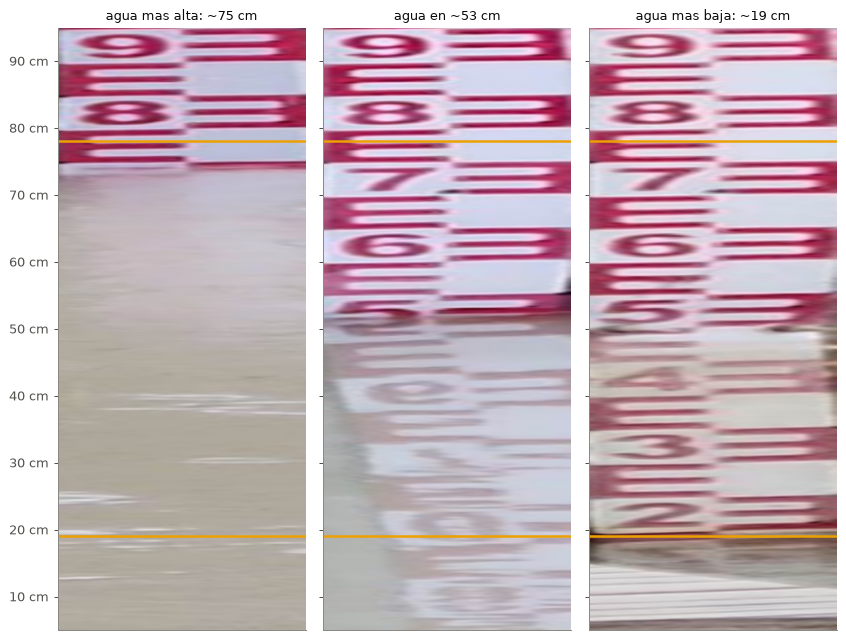

In [6]:
NIVEL_MINIMO = 19.0           # >>> AJUSTABLE <<< cm: en la foto de agua mas baja el agua esta en ~18 cm; por debajo no hay lectura
NIVEL_MAX_AGUA = 78.0         # >>> AJUSTABLE <<< cm: por encima la mira esta siempre seca en esta serie (visto en las fotos)
NIVEL_MIN_BUSQUEDA = 12.0     # >>> AJUSTABLE <<< cm: se busca algo por debajo del minimo para detectar ese caso

fig, ax = plt.subplots(1, 3, figsize=(9.5, 7.2), sharey=True)
for a, archivo, titulo in zip(ax, ["20230704/images/P23070414111910.jpg", FOTO, "20230619/images/P23061911412010.jpg"],
                              ["agua mas alta: ~75 cm", "agua en ~53 cm", "agua mas baja: ~19 cm"]):
    a.imshow(rgb(T.enderezar(leer(archivo))), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic")
    a.axhline(T.fila_de(NIVEL_MAX_AGUA), color=AMARILLO, lw=2); a.axhline(T.fila_de(NIVEL_MINIMO), color=AMARILLO, lw=2)
    a.set_xticks([]); a.set_title(titulo, fontsize=10, color=TINTA)
ax[0].set_yticks([T.fila_de(c) for c in niveles]); ax[0].set_yticklabels(["%d cm" % c for c in niveles])
ax[0].set_ylim(T.fila_de(5), 0)
plt.tight_layout()

## 1.7 El algoritmo de la linea de agua

Es el del notebook 01, sin tocar una linea. Para cada fila candidata: una **ventana** de 8 cm arriba y otra abajo, se **voltea** la de arriba y se **compara** con correlacion normalizada (NCC); la fila con mas parecido es la **linea de agua**. Solo cambian las columnas, por el ancho de esta mira.

Foto de ejemplo: fila 203 del tablero, 72.4 cm, parecido 0.65. A ojo, el agua esta en ~53 cm.


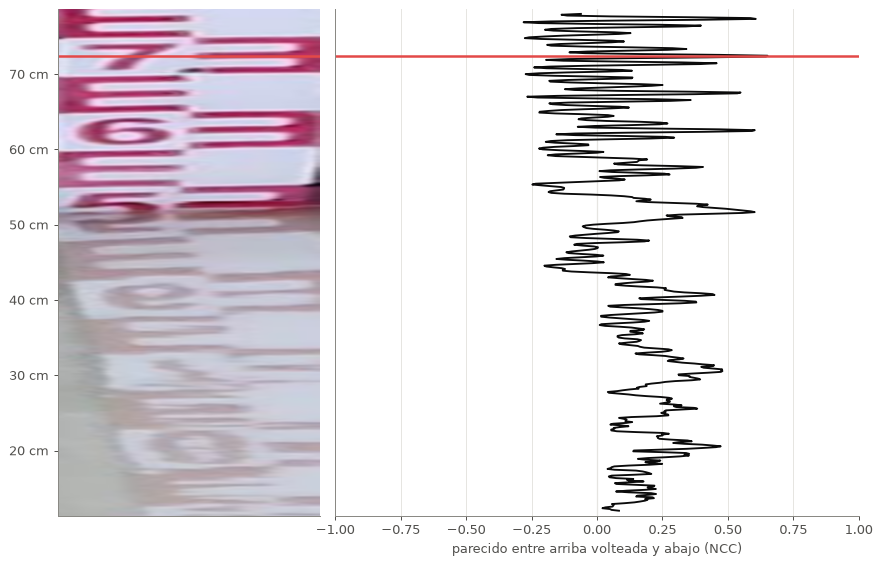

In [7]:
VENTANA_CM = 8.0           # >>> AJUSTABLE <<< alto de cada ventana
H = int(VENTANA_CM * PX_POR_CM)
COLUMNAS = (3, 51)         # >>> AJUSTABLE <<< columnas del tablero que se comparan (dentro de la placa)


def ncc(a, b):
    a = a - a.mean()
    b = b - b.mean()
    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum() + 1e-9))


def ventanas(R, y, h=H, cols=COLUMNAS):
    # arriba volteada y abajo, listas para comparar
    return R[y - h:y, cols[0]:cols[1]][::-1], R[y:y + h, cols[0]:cols[1]]


def curva_espejo(R, filas, h=H, cols=COLUMNAS):
    return np.array([ncc(*ventanas(R, y, h, cols)) for y in filas])


def espejo(R, nivel_max=NIVEL_MAX_AGUA, nivel_min=NIVEL_MIN_BUSQUEDA, h=H):
    # devuelve la fila del tablero con mas parecido en espejo, su parecido, y la curva entera
    filas = np.arange(max(int(T.fila_de(nivel_max)), h), min(int(T.fila_de(nivel_min)), R.shape[0] - h) + 1)
    s = curva_espejo(R, filas, h)
    k = int(np.argmax(s))
    return int(filas[k]), float(s[k]), filas, s


R = T.enderezar(gris(img))
fila_ej, parecido_ej, filas_ej, curva_ej = espejo(R)
print("Foto de ejemplo: fila %d del tablero, %.1f cm, parecido %.2f. A ojo, el agua esta en ~53 cm." % (fila_ej, T.nivel_de(fila_ej), parecido_ej))

fig, ax = plt.subplots(1, 2, figsize=(10, 6.4), sharey=True, gridspec_kw={"width_ratios": [0.6, 1.2], "wspace": 0.04})
ax[0].imshow(rgb(tablero), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic")
ax[0].set_xticks([]); ax[0].set_yticks([T.fila_de(c) for c in niveles]); ax[0].set_yticklabels(["%d cm" % c for c in niveles])
ax[1].plot(curva_ej, filas_ej, color=TINTA, lw=1.5)
ax[1].axvline(0, color=REJILLA, lw=1, zorder=0)
ax[1].grid(axis="x", color=REJILLA, lw=0.8); ax[1].set_axisbelow(True)
for a in ax:
    a.axhline(fila_ej, color=ROJO, lw=2)
ax[1].set_xlim(-1, 1); ax[1].set_xlabel("parecido entre arriba volteada y abajo (NCC)")
ax[1].set_ylim(filas_ej[-1] + 6, filas_ej[0] - 6)
plt.setp(ax[1].get_yticklabels(), visible=False); ax[1].tick_params(axis="y", length=0)
fig.subplots_adjust(left=0.09, right=0.98, top=0.97, bottom=0.09)

## 1.8 De la fila al nivel, y las secciones

`medir_foto` y `marcar_saltos` son las del notebook 01. La conversion es la misma resta: aqui `nivel (cm) = 95 - fila / 9`. Un **salto** es una lectura a mas de 3 cm de la mediana de las 7 fotos que la rodean: es solo un diagnostico, nada se filtra.

Para ver el resultado se usa un **quimograma**: el perfil vertical de la mira de cada foto, uno junto a otro; el tiempo va en horizontal y el nivel en vertical. El agua se ve como el borde donde acaba el dibujo nitido, y los puntos son la lectura. Las noches se aclaran solo para verlas.

,fotos,lee_sobre_62_cm,saltos,parecido_mediano
seccion,,,,
"dia, agua quieta",46,44,2,0.67
noche,36,12,9,0.80
"dia, agua rizada",26,15,8,0.66
vaciado,90,79,12,0.69
cambio brusco,36,20,20,0.68


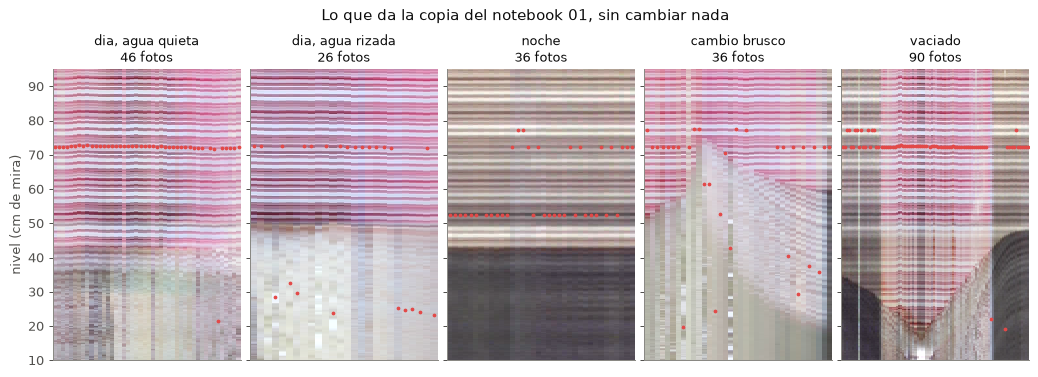

In [8]:
def medir_foto(archivo):
    R = T.enderezar(gris(leer(archivo)))
    fila, parecido, _, _ = espejo(R)
    nivel = T.nivel_de(fila)
    return {"archivo": archivo, "hora": hora_de(archivo), "fila_tablero": fila,
            "fila_foto": float(T.a_foto(ANCHO / 2, fila)[1]), "nivel_bruto_cm": nivel,
            "parecido": parecido, "bajo_minimo": bool(nivel < NIVEL_MINIMO)}


SALTO_CM = 3.0     # solo para contar saltos: el metodo basico no filtra nada


def marcar_saltos(serie):
    m = np.array([np.median(serie[max(i - 3, 0):i + 4]) for i in range(len(serie))])
    return np.abs(serie - m) > SALTO_CM


def medir_secciones():
    # recorre las fotos de las secciones, en paralelo, y marca los saltos dentro de cada bloque
    with ThreadPoolExecutor(8) as ex:
        d = pd.DataFrame(list(ex.map(medir_foto, fotos_s))).sort_values("hora").reset_index(drop=True)
    d["seccion"] = [seccion_de(a) for a in d.archivo]
    d["nivel_m"] = np.where(d.bajo_minimo, np.nan, d.nivel_bruto_cm / 100)
    d["salto"] = d.groupby("seccion").nivel_bruto_cm.transform(lambda s: marcar_saltos(s.values)).astype(bool)
    return d


def preparar(archivo):
    c = leer(archivo)
    return archivo, T.enderezar(c)


with ThreadPoolExecutor(8) as ex:
    tiras_s = dict(ex.map(preparar, fotos_s))


def dibujar_secciones(lecturas, titulo=None, alto=4.2):
    # un quimograma por seccion. lecturas: [(dataframe, color, tamano), ...]
    fig, ax = plt.subplots(1, len(SECCIONES), figsize=(14, alto), sharey=True, gridspec_kw={"wspace": 0.05})
    for a, s in zip(ax, SECCIONES):
        lista = [x for x in fotos_s if seccion_de(x) == s]
        cols = []
        for x in lista:
            p = tiras_s[x][:, 8:46].mean(1)
            cols.append(np.clip(p * 230.0 / max(np.percentile(p[:int(T.fila_de(78))], 90), 1), 0, 255))
        K = np.stack(cols, 1).astype(np.uint8)
        a.imshow(K[:, :, ::-1], extent=[0, K.shape[1], T.nivel_de(K.shape[0]), T.nivel_sup], aspect="auto", interpolation="nearest")
        for d, color, ms in lecturas:
            ds = d.set_index("archivo").reindex(lista)
            a.plot(np.arange(len(lista)) + 0.5, ds.nivel_bruto_cm.where(~ds.bajo_minimo.astype(bool)), ".", ms=ms, color=color)
        a.set_ylim(10, 95); a.set_xticks([]); a.set_title("%s\n%d fotos" % (s, len(lista)), fontsize=10, color=TINTA)
    ax[0].set_ylabel("nivel (cm de mira)")
    if titulo:
        fig.suptitle(titulo, color=TINTA, y=1.04)


df_v1 = medir_secciones()
df_v1.to_csv(os.path.join(SALIDAS, "02_v1_secciones.csv"), index=False, float_format="%.4f")
dibujar_secciones([(df_v1, ROJO, 4)], "Lo que da la copia del notebook 01, sin cambiar nada")
df_v1.groupby("seccion", sort=False).agg(fotos=("archivo", "size"), lee_sobre_62_cm=("nivel_bruto_cm", lambda s: int((s > 62).sum())),
                                         saltos=("salto", "sum"), parecido_mediano=("parecido", "median")).round(2)

## 1.9 Que cambio exactamente en esta copia

Se calcula leyendo el codigo de los dos notebooks, no a mano. Primero, los valores de configuracion:

In [9]:
NB_01, NB_02 = "01_meguro_algoritmo_basico.ipynb", "02_lago_china_primera_mejora.ipynb"


def celdas_codigo(ruta):
    nb = json.load(open(ruta, encoding="utf-8"))
    return ["".join(c["source"]) for c in nb["cells"] if c["cell_type"] == "code"]


def definiciones(ruta):
    # funciones y clases de primer nivel, en orden: [(nombre, codigo), ...]
    salida = []
    for codigo in celdas_codigo(ruta):
        for nodo in ast.parse(codigo).body:
            if isinstance(nodo, (ast.FunctionDef, ast.ClassDef)):
                salida.append((nodo.name, "\n".join(codigo.splitlines()[nodo.lineno - 1:nodo.end_lineno])))
    return salida


def asignaciones(ruta):
    # primer valor escrito para cada nombre en una asignacion de primer nivel: {nombre: texto}
    salida = {}
    for codigo in celdas_codigo(ruta):
        for nodo in ast.parse(codigo).body:
            if isinstance(nodo, ast.Assign) and len(nodo.targets) == 1:
                obj, val = nodo.targets[0], nodo.value
                pares = zip(obj.elts, val.elts) if isinstance(obj, ast.Tuple) and isinstance(val, ast.Tuple) else [(obj, val)]
                for o, v in pares:
                    if isinstance(o, ast.Name):
                        salida.setdefault(o.id, ast.get_source_segment(codigo, v))
    return salida


defs_01, defs_02 = definiciones(NB_01), definiciones(NB_02)
a01, a02 = asignaciones(NB_01), asignaciones(NB_02)
CONFIGURACION = ["DATOS", "CARPETA_FOTOS", "TEXTO_NIVEL", "FOTO", "BORDE_IZQ", "BORDE_DER", "NIVEL_SUP", "FILA_SUP", "NIVEL_INF", "FILA_INF", "PX_POR_CM", "ANCHO",
                 "EXTRA_CM", "MARCAS_CONTROL", "NIVEL_MINIMO", "NIVEL_MAX_AGUA", "NIVEL_MIN_BUSQUEDA", "VENTANA_CM", "COLUMNAS", "H", "SALTO_CM"]
tabla_config = pd.DataFrame([{"valor": n, "Meguro": a01.get(n, "-"), "China": a02.get(n, "-"), "igual": a01.get(n) == a02.get(n)} for n in CONFIGURACION]).set_index("valor")
pd.set_option("display.max_colwidth", 70)
tabla_config

,Meguro,China,igual
valor,,,
DATOS,"os.path.join("".."", ""05_tokio_meguro_suimon"", ""datos"")","os.path.join("".."", ""01_zenodo_lago_china"", ""datos"", ""SAM_water_lev...",False
CARPETA_FOTOS,"os.path.join(DATOS, ""capturas"")","os.path.join(DATOS, ""Staff gauge images"")",False
TEXTO_NIVEL,"(430, 15, 960, 95)","(0, 0, 0, 0)",False
FOTO,"""20261020_142000.jpg""","""20230706/images/P23070610561710.jpg""",False
BORDE_IZQ,"[(647, 160), (650, 510)]","[(2002, 1200), (1980, 1742)]",False
BORDE_DER,"[(705, 160), (707, 510)]","[(2056, 1200), (2033, 1742)]",False
NIVEL_SUP,350.0,95.0,False
FILA_SUP,148.0,1119.5,False
NIVEL_INF,150.0,25.0,False


Y luego el codigo: que funciones son identicas, linea a linea, a las del notebook 01.

In [10]:
primera_01, primera_02 = {}, {}
for n, f in defs_01:
    primera_01.setdefault(n, f)
for n, f in defs_02:
    primera_02.setdefault(n, f)
METODO = ["leer", "rgb", "gris", "recta_por", "Tablero", "fila_homografia", "ncc", "ventanas", "curva_espejo", "espejo", "medir_foto", "marcar_saltos"]
for n in METODO:
    print("%-16s %s" % (n, "identica al notebook 01" if primera_01[n] == primera_02[n] else "DISTINTA"))
print("\nDistinta por el nombre de los archivos, no es del metodo:")
print("\n".join(l for l in difflib.unified_diff(primera_01["hora_de"].splitlines(), primera_02["hora_de"].splitlines(), "notebook 01", "esta copia", lineterm="", n=0)))
assert all(primera_01[n] == primera_02[n] for n in METODO)

leer             identica al notebook 01
rgb              identica al notebook 01
gris             identica al notebook 01
recta_por        identica al notebook 01
Tablero          identica al notebook 01
fila_homografia  identica al notebook 01
ncc              identica al notebook 01
ventanas         identica al notebook 01
curva_espejo     identica al notebook 01
espejo           identica al notebook 01
medir_foto       identica al notebook 01
marcar_saltos    identica al notebook 01

Distinta por el nombre de los archivos, no es del metodo:
--- notebook 01
+++ esta copia
@@ -2,2 +2,2 @@
-    # 20261020_124454.jpg -> 2026-10-20 12:44:54 (hora de Japon en que se pidio el frame)
-    return datetime.strptime(os.path.basename(archivo)[:15], "%Y%m%d_%H%M%S")
+    # P23052700112410.jpg -> 2023-05-27 00:11:24 (hora local que imprime la camara)
+    return datetime.strptime(os.path.basename(archivo)[1:13], "%y%m%d%H%M%S")


**Lo que no es del metodo y si cambia en esta copia:**

- las fotos no se guardan en memoria, porque 4K no caben;
- se recorren en paralelo y por secciones;
- las figuras se adaptan a esta mira;
- se omiten "Lo que no funciono" de Meguro, y la comparacion y el video pasan a la parte 4, porque la referencia solo se abre una vez.

# 2. Problemas

## 2.1 Lo que no da problema

- **La inclinacion.** La mira esta inclinada 2.3 grados, y enderezar ya lo resuelve sin codigo nuevo: el reflejo queda en el mismo plano que la mira. En la figura, las mismas ventanas con y sin enderezar: enderezar no empeora el parecido.
- **La escala.** Hay cinco veces mas detalle que en Meguro y nada cambia: ventanas y rango van en cm.
- **El tablero.** Las marcas de control caen a menos de 0.3 cm (1.5).
- **Las fotos rotas** no paran la serie: siguen dando un numero, y eso si es un problema (2.4).

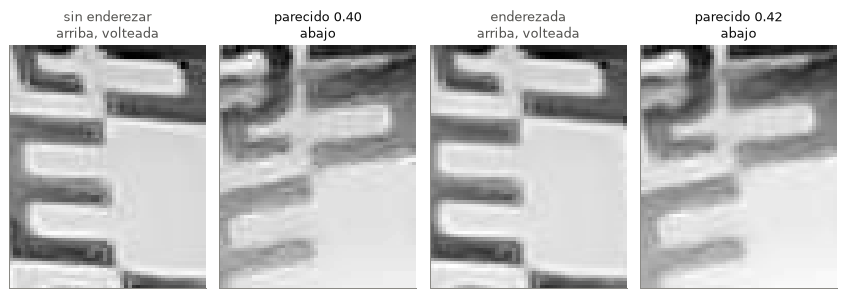

In [11]:
nivel_ojo = 52.6             # la linea de agua de la foto de ejemplo, leida a ojo
fila_t = int(T.fila_de(nivel_ojo))
col_c = ANCHO / 2
x_f, y_f = T.a_foto(col_c, fila_t)
h_f = int(VENTANA_CM * (FILA_INF - FILA_SUP) / (NIVEL_SUP - NIVEL_INF))
x0_f, x1_f, y_f = int(x_f - 24), int(x_f + 24), int(y_f)
gris_img = gris(img)
casos = [("sin enderezar", gris_img[y_f - h_f:y_f, x0_f:x1_f][::-1], gris_img[y_f:y_f + h_f, x0_f:x1_f]), ("enderezada", *ventanas(R, fila_t))]
fig, ax = plt.subplots(1, 4, figsize=(9.5, 3.4))
for i, (nombre, arriba, abajo) in enumerate(casos):
    ax[2 * i].imshow(arriba, cmap="gray", aspect="auto"); ax[2 * i + 1].imshow(abajo, cmap="gray", aspect="auto")
    ax[2 * i].set_title("%s\narriba, volteada" % nombre, fontsize=10, color=TINTA2)
    ax[2 * i + 1].set_title("parecido %.2f\nabajo" % ncc(arriba, abajo), fontsize=10, color=TINTA)
    for a in ax[2 * i:2 * i + 2]:
        a.set_xticks([]); a.set_yticks([])
plt.tight_layout()

## 2.2 Problema 1: el pico cae sobre la mira seca

El 8, el 7, el 6 y las E son simetricos consigo mismos: partidos por la mitad, lo de arriba volteado se parece a lo de abajo, y ademas nitido. El reflejo de verdad es mas palido y esta movido. **Cualquier numero seco le gana al agua.** En Meguro se evitaba buscando solo en el bloque del agua; aqui el agua llega a 75 cm, y en esa zona hay numeros y E. Y al ser un dibujo repetido, limitar mas el rango tampoco serviria.

Buscando en toda la regla: 82.3 cm, parecido 0.77


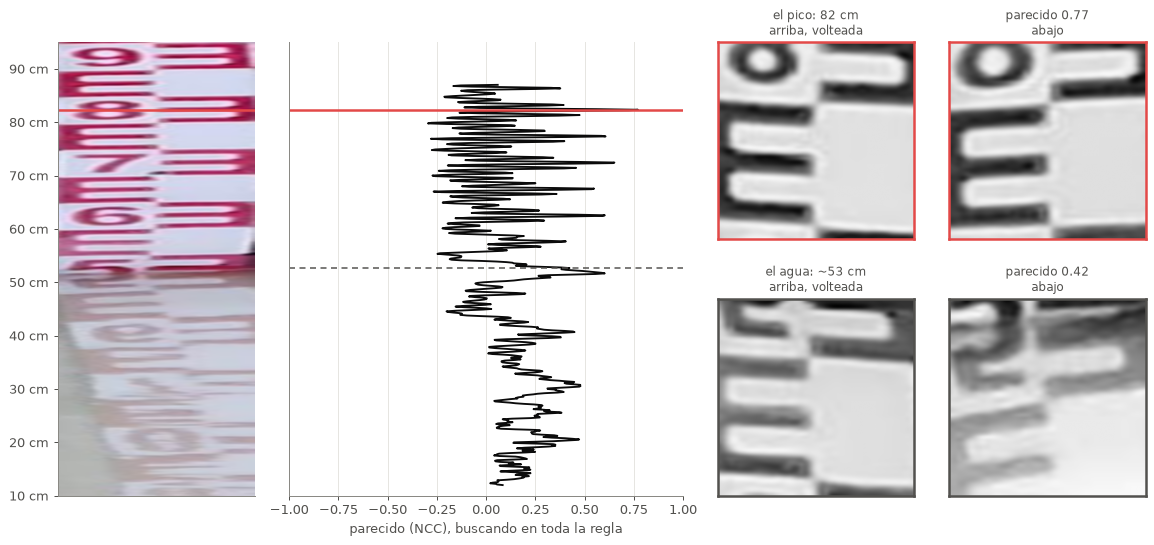

In [12]:
fila_toda, par_toda, filas_toda, curva_toda = espejo(R, nivel_max=NIVEL_SUP)
fig = plt.figure(figsize=(13, 6))
gs = fig.add_gridspec(2, 4, width_ratios=[0.55, 1.1, 0.55, 0.55], wspace=0.14, hspace=0.3)
a0 = fig.add_subplot(gs[:, 0])
a1 = fig.add_subplot(gs[:, 1], sharey=a0)
a0.imshow(rgb(tablero), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic")
a0.axhline(fila_toda, color=ROJO, lw=2); a0.set_xticks([])
a0.set_yticks([T.fila_de(c) for c in niveles]); a0.set_yticklabels(["%d cm" % c for c in niveles])
a1.plot(curva_toda, filas_toda, color=TINTA, lw=1.5)
a1.axhline(fila_toda, color=ROJO, lw=2); a1.axhline(fila_t, color=TINTA2, lw=1.2, ls=(0, (4, 3)))
a1.set_xlim(-1, 1); a1.set_xlabel("parecido (NCC), buscando en toda la regla")
a1.grid(axis="x", color=REJILLA, lw=0.8); a1.set_axisbelow(True)
plt.setp(a1.get_yticklabels(), visible=False); a1.tick_params(axis="y", length=0)
a0.set_ylim(T.fila_de(10), T.fila_de(95))
for i, (fila, col, nombre) in enumerate([(fila_toda, ROJO, "el pico: %.0f cm" % T.nivel_de(fila_toda)), (fila_t, TINTA2, "el agua: ~53 cm")]):
    arriba, abajo = ventanas(R, fila)
    for j, (v, t_) in enumerate([(arriba, "arriba, volteada"), (abajo, "abajo")]):
        a = fig.add_subplot(gs[i, j + 2])
        a.imshow(v, cmap="gray", aspect="auto", interpolation="bicubic"); a.set_xticks([]); a.set_yticks([])
        a.set_title("%s\n%s" % (nombre, t_) if j == 0 else "parecido %.2f\n%s" % (ncc(arriba, abajo), t_), fontsize=9.5, color=TINTA2)
        for sp in a.spines.values():
            sp.set_visible(True); sp.set_color(col); sp.set_linewidth(2)
fig.subplots_adjust(left=0.06, right=0.99, top=0.92, bottom=0.08)
print("Buscando en toda la regla: %.1f cm, parecido %.2f" % (T.nivel_de(fila_toda), par_toda))